# Practical Work 4 — Linear Regression and Gradient Descent

**Project:** MACHINEGUARD  
**Level:** C

## Objective

To implement linear regression using NumPy, calculate the Mean Squared Error and its gradient manually, compare different learning rates, and evaluate the results against Scikit-learn LinearRegression.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("MACHINEGUARD PR4")
print("All libraries imported successfully!")



MACHINEGUARD PR4
All libraries imported successfully!


In [2]:

project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

df = pd.read_csv(
    project_dir / "data" / "raw" / "ai4i2020.csv"
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:

features = [
    "Rotational speed [rpm]",
    "Air temperature [K]",
    "Process temperature [K]",
    "Tool wear [min]"
]

target = "Torque [Nm]"

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_array = y_train.to_numpy()

print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)


Training: (8000, 4)
Testing: (2000, 4)


In [4]:

def mse_numpy(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def compute_gradient(X, y, weights, bias):
    n = len(y)

    predictions = X @ weights + bias
    errors = predictions - y

    dw = (2 / n) * (X.T @ errors)
    db = (2 / n) * np.sum(errors)

    return dw, db


test_true = np.array([10, 20, 30])
test_pred = np.array([12, 18, 33])

print("Test MSE:", mse_numpy(test_true, test_pred))


Test MSE: 5.666666666666667


In [5]:

def gradient_descent(X, y, learning_rate=0.01, iterations=2000):
    n_features = X.shape[1]

    weights = np.zeros(n_features)
    bias = 0.0
    history = []

    for i in range(iterations):
        predictions = X @ weights + bias

        dw, db = compute_gradient(
            X, y, weights, bias
        )

        weights -= learning_rate * dw
        bias -= learning_rate * db

        updated_predictions = X @ weights + bias
        loss = mse_numpy(y, updated_predictions)
        history.append(loss)

    return weights, bias, history


weights, bias, history = gradient_descent(
    X_train_scaled,
    y_train_array,
    learning_rate=0.01,
    iterations=2000
)

print("Weights:", np.round(weights, 4))
print("Bias:", round(bias, 4))
print("Initial MSE:", round(history[0], 4))
print("Final MSE:", round(history[-1], 4))


Weights: [-8.7454  0.2244 -0.1644 -0.0475]
Bias: 40.0078
Initial MSE: 1633.7815
Final MSE: 23.1047


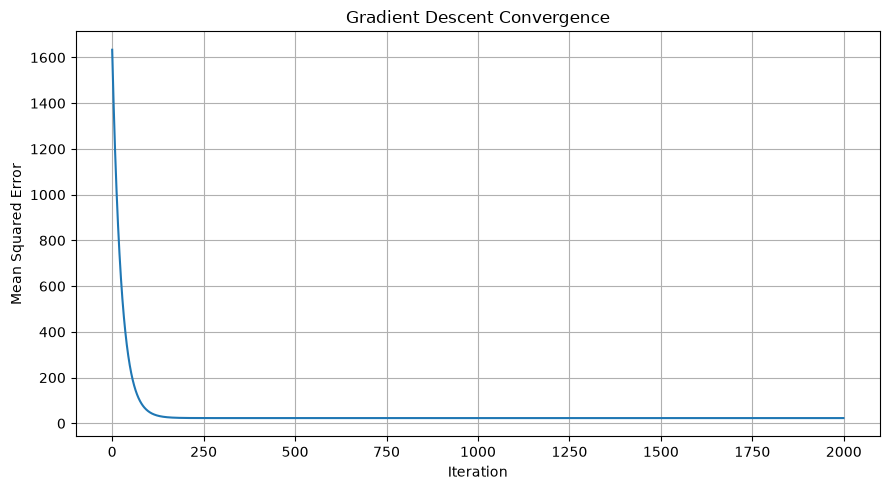

In [6]:

plt.figure(figsize=(9, 5))

plt.plot(history)

plt.title("Gradient Descent Convergence")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.tight_layout()
plt.show()


### Gradient Descent Convergence

The convergence graph shows how the Mean Squared Error decreases during model training.

The decreasing curve indicates that gradient descent successfully updates the model parameters to reduce prediction errors.

The stabilization of the curve suggests that the optimization algorithm is approaching convergence.

Learning rate 0.001: Final MSE = 23.6666
Learning rate 0.01: Final MSE = 23.1047
Learning rate 0.1: Final MSE = 23.1047


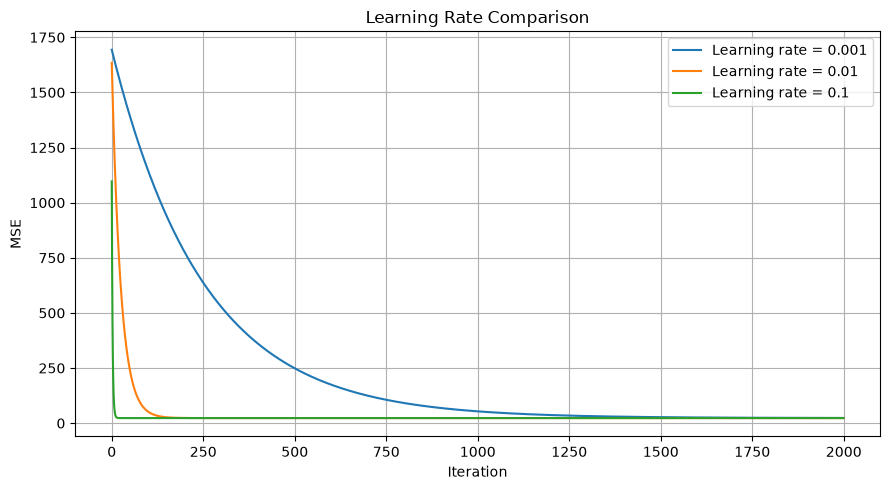

In [7]:

learning_rates = [0.001, 0.01, 0.1]

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    w, b, losses = gradient_descent(
        X_train_scaled,
        y_train_array,
        learning_rate=lr,
        iterations=2000
    )

    print(
        f"Learning rate {lr}: "
        f"Final MSE = {losses[-1]:.4f}"
    )

    plt.plot(losses, label=f"Learning rate = {lr}")

plt.title("Learning Rate Comparison")
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Learning Rate Comparison

Three learning rates were evaluated: 0.001, 0.01, and 0.1.

The experiment demonstrates the influence of learning rate on optimization speed.

A smaller learning rate generally requires more iterations, while a larger learning rate may converge faster but can become unstable.

The convergence curves and final MSE values are used to compare the learning rates.

In [8]:

sklearn_model = LinearRegression()
sklearn_model.fit(X_train_scaled, y_train_array)

numpy_predictions = X_test_scaled @ weights + bias
sklearn_predictions = sklearn_model.predict(X_test_scaled)

comparison = pd.DataFrame({
    "Metric": ["MSE", "MAE", "R2"],
    "NumPy Gradient Descent": [
        mean_squared_error(y_test, numpy_predictions),
        mean_absolute_error(y_test, numpy_predictions),
        r2_score(y_test, numpy_predictions)
    ],
    "Scikit-learn": [
        mean_squared_error(y_test, sklearn_predictions),
        mean_absolute_error(y_test, sklearn_predictions),
        r2_score(y_test, sklearn_predictions)
    ]
})

display(comparison)

print("NumPy weights:", np.round(weights, 4))
print("Scikit-learn weights:", np.round(sklearn_model.coef_, 4))
print("NumPy bias:", round(bias, 4))
print("Scikit-learn bias:", round(sklearn_model.intercept_, 4))


,Metric,NumPy Gradient Descent,Scikit-learn
0,MSE,23.989055,23.989293
1,MAE,3.686180,3.686211
2,R2,0.756593,0.756591


NumPy weights: [-8.7454  0.2244 -0.1644 -0.0475]
Scikit-learn weights: [-8.7454  0.2259 -0.1659 -0.0475]
NumPy bias: 40.0078
Scikit-learn bias: 40.0078


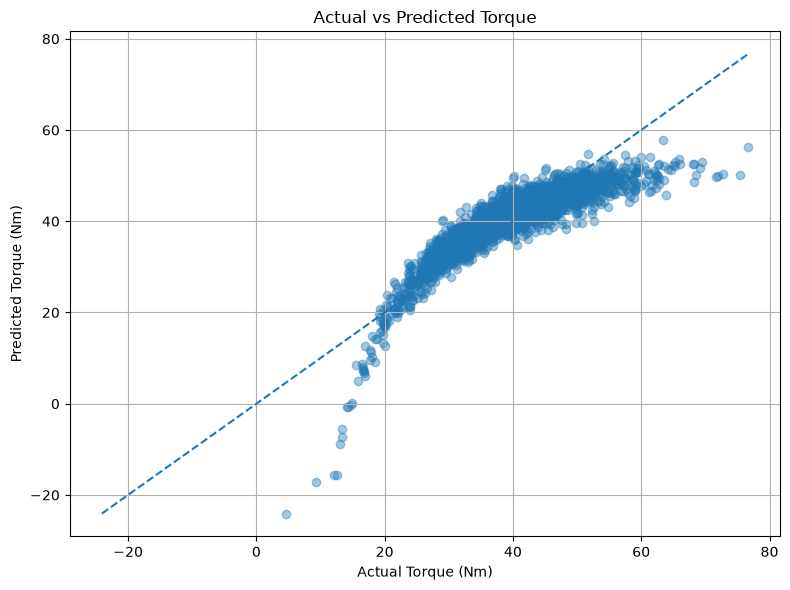

In [9]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    sklearn_predictions,
    alpha=0.4
)

minimum = min(y_test.min(), sklearn_predictions.min())
maximum = max(y_test.max(), sklearn_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Torque")
plt.xlabel("Actual Torque (Nm)")
plt.ylabel("Predicted Torque (Nm)")

plt.grid(True)
plt.tight_layout()
plt.show()


### Actual vs Predicted Torque

The scatter plot compares actual torque values with predictions produced by Scikit-learn LinearRegression.

The dashed diagonal line represents perfect predictions.

Points closer to the diagonal indicate smaller prediction errors, while points farther away indicate larger differences between actual and predicted values.

## Final Conclusions

Practical Work 4 focused on implementing linear regression using NumPy and understanding gradient descent.

The Mean Squared Error function and its gradients were implemented manually.

The model was trained to predict torque using machine operating features.

Three learning rates were compared to examine convergence behavior.

The NumPy implementation was evaluated against Scikit-learn LinearRegression using MSE, MAE, R2, and model coefficients.

The results demonstrate how gradient descent optimizes linear regression parameters and how its performance can be validated using a standard machine learning library.